## 1. Import Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")


## 2. Load the Datasets

In [3]:
# Load the dataset
df = pd.read_csv("AI4I_with_synthetic_data_cleaned_data.csv")

# Display the first 5 rows
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 3. Dataset Information

In [4]:
# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names and data types
df.info()

Dataset shape: (12500, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12500 entries, 0 to 12499
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      12500 non-null  int64  
 1   Product ID               12500 non-null  object 
 2   Type                     12500 non-null  object 
 3   Air temperature [K]      12500 non-null  float64
 4   Process temperature [K]  12500 non-null  float64
 5   Rotational speed [rpm]   12500 non-null  int64  
 6   Torque [Nm]              12500 non-null  float64
 7   Tool wear [min]          12500 non-null  int64  
 8   Machine failure          12500 non-null  int64  
 9   TWF                      12500 non-null  int64  
 10  HDF                      12500 non-null  int64  
 11  PWF                      12500 non-null  int64  
 12  OSF                      12500 non-null  int64  
 13  RNF                      12500 non-null  int64  


## 4. Check Missing Values and Duplicates

In [5]:
# Count missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Count duplicated rows
print("\nDuplicated rows:", df.duplicated().sum())


Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicated rows: 0


## 5. Statistical Summary

In [6]:
# Display statistical information for numerical columns
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,1.250000e+04,12500.000000,12500.000000,12500.000000,12500.000000,12500.000000,12500.000000,12500.000000,12500.000000,12500.000000,12500.000000,12500.000000
mean,1.651514e+06,300.180552,310.098272,1520.993280,41.437256,115.139200,0.227120,0.050400,0.056080,0.056800,0.061280,0.042640
std,3.955283e+06,2.097192,1.601404,175.836138,12.602705,67.433439,0.418988,0.218778,0.230085,0.231469,0.239853,0.202052
min,1.000000e+00,295.300000,305.700000,1168.000000,8.950000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.125750e+03,298.400000,308.800000,1398.000000,32.800000,57.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,6.250500e+03,300.200000,310.200000,1496.000000,40.900000,116.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.375250e+03,301.900000,311.300000,1620.000000,48.700000,176.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.677667e+07,304.500000,313.800000,1953.000000,72.550000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## 6. Machine Failure Distribution

Machine failure
0    9661
1    2839
Name: count, dtype: int64
Machine failure
0    77.288
1    22.712
Name: proportion, dtype: float64


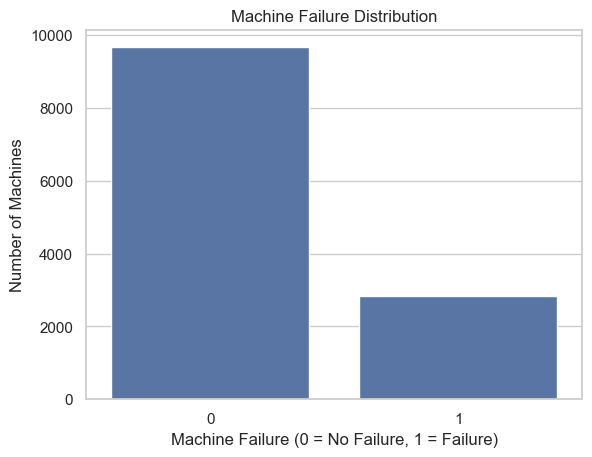

In [7]:
# Count machines that failed and machines that did not fail
print(df["Machine failure"].value_counts())

# Display the percentages
print(df["Machine failure"].value_counts(normalize=True) * 100)

# Visualize the distribution
sns.countplot(data=df, x="Machine failure")

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Machines")
plt.show()

## 7. Failure Type Distribution

TWF    630
HDF    701
PWF    710
OSF    766
RNF    533
dtype: int64


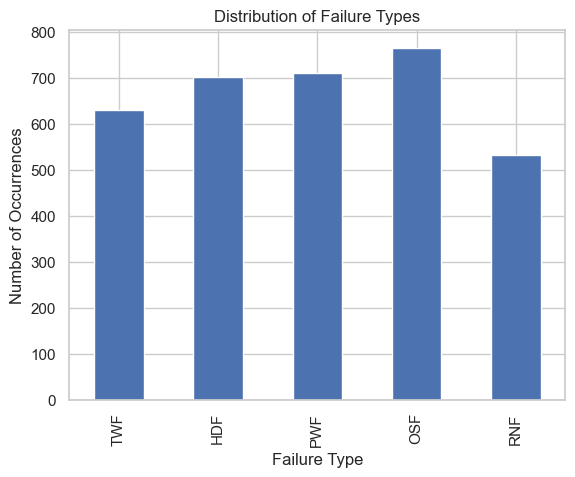

In [8]:
# These columns represent different failure types
failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Count the occurrences of each failure type
print(df[failure_types].sum())

# Visualize the results
df[failure_types].sum().plot(kind="bar")

plt.title("Distribution of Failure Types")
plt.xlabel("Failure Type")
plt.ylabel("Number of Occurrences")
plt.show()

## 8. Check Failure Labels

In [9]:
# Compare Machine failure with the individual failure-type indicators
failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Count rows where at least one failure type is recorded
has_failure_type = df[failure_types].any(axis=1)

# Compare the failure indicator with the target
mismatch = df["Machine failure"] != has_failure_type

print("Rows with mismatched failure labels:", mismatch.sum())

Rows with mismatched failure labels: 27


## 9. Failure Rate by Product Type

Type
H    23.579767
L    24.403357
M    18.807467
Name: Machine failure, dtype: float64


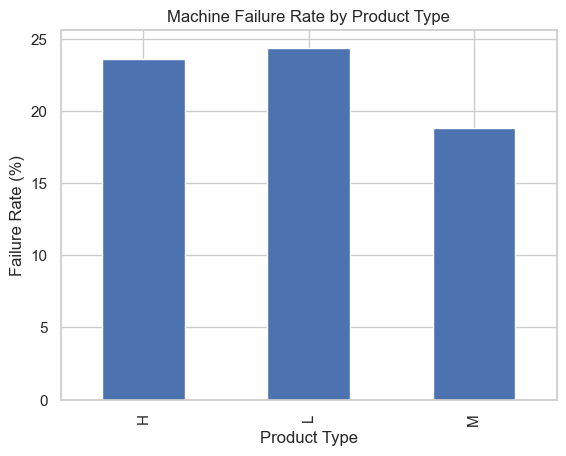

In [10]:
# Calculate the average failure rate for each product type
failure_by_type = df.groupby("Type")["Machine failure"].mean() * 100

print(failure_by_type)

# Visualize the failure rate
failure_by_type.plot(kind="bar")

plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")
plt.show()

## 10. Feature Distributions

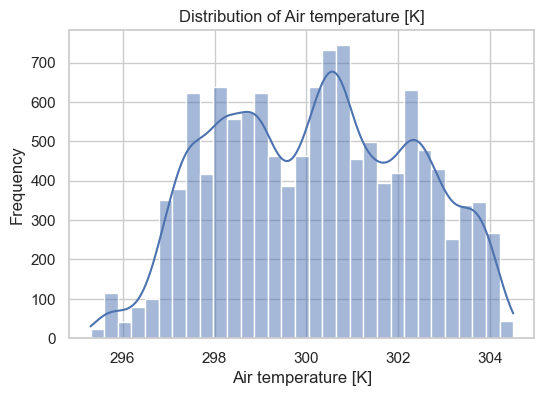

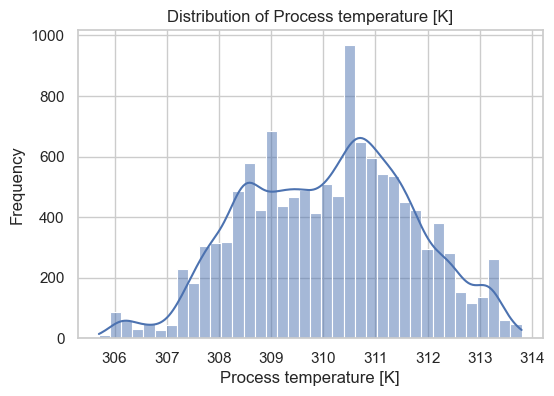

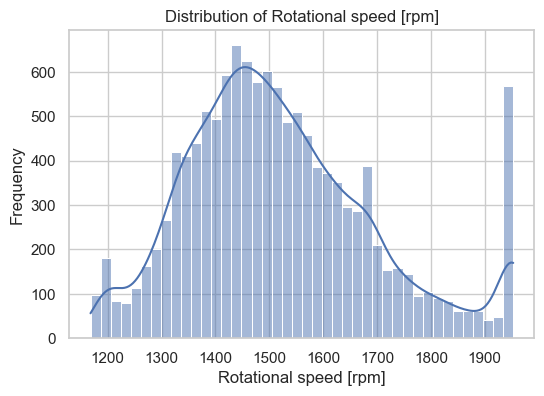

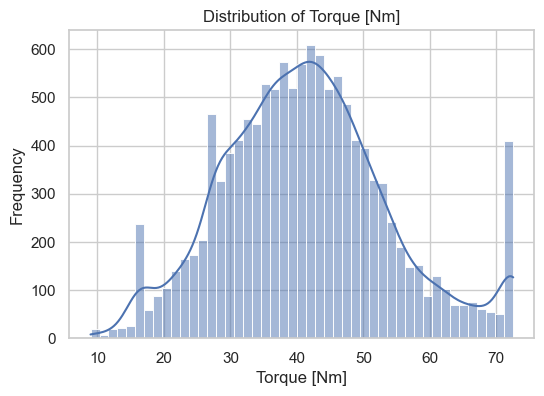

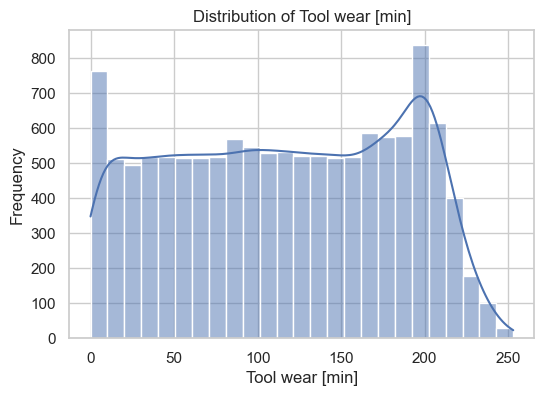

In [11]:
# Sensor features
num_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Display a histogram for each feature
for col in num_cols:
    plt.figure(figsize=(6, 4))

    sns.histplot(data=df, x=col, kde=True)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

## 11. Compare Features with Machine Failure

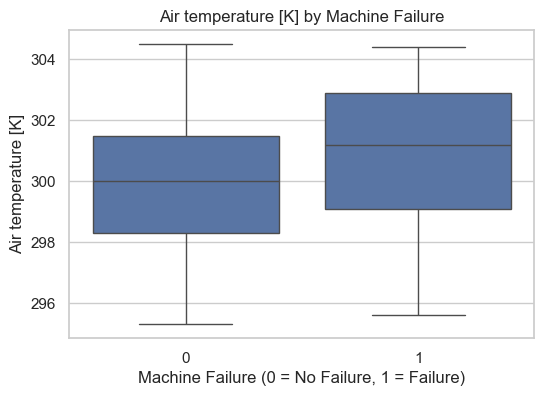

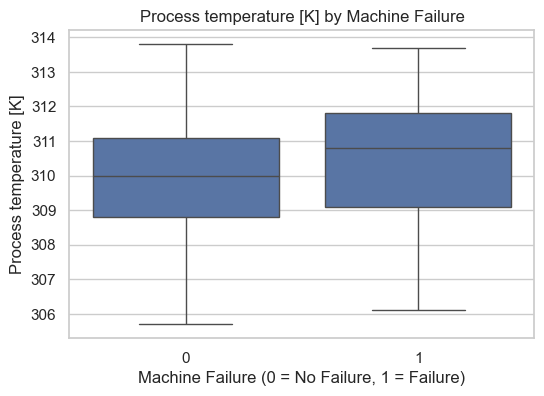

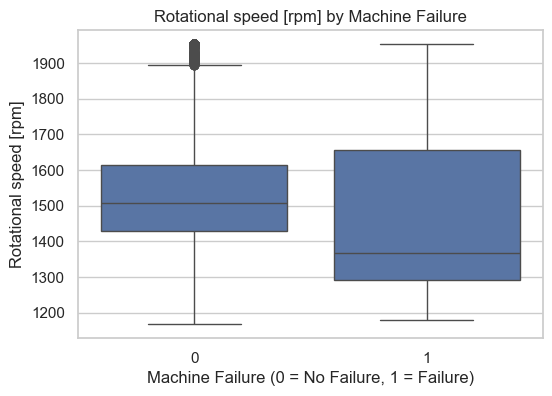

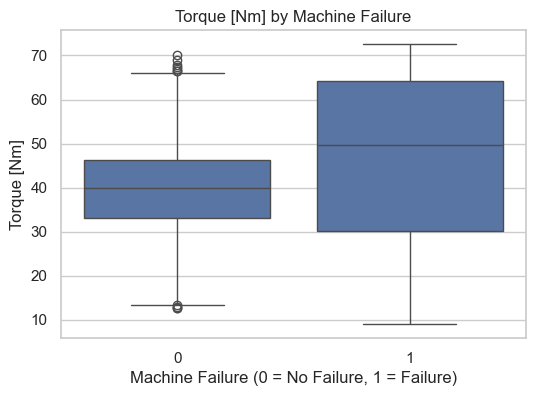

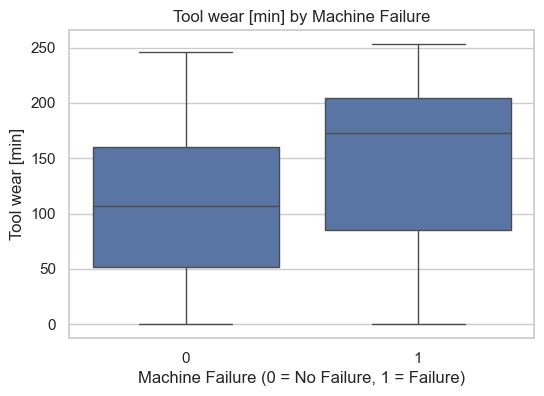

In [12]:
# Compare each sensor feature between failed and non-failed machines
for col in num_cols:
    plt.figure(figsize=(6, 4))

    sns.boxplot(data=df, x="Machine failure", y=col)

    plt.title(f"{col} by Machine Failure")
    plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
    plt.ylabel(col)

    plt.show()

## 12. Correlation Heatmap

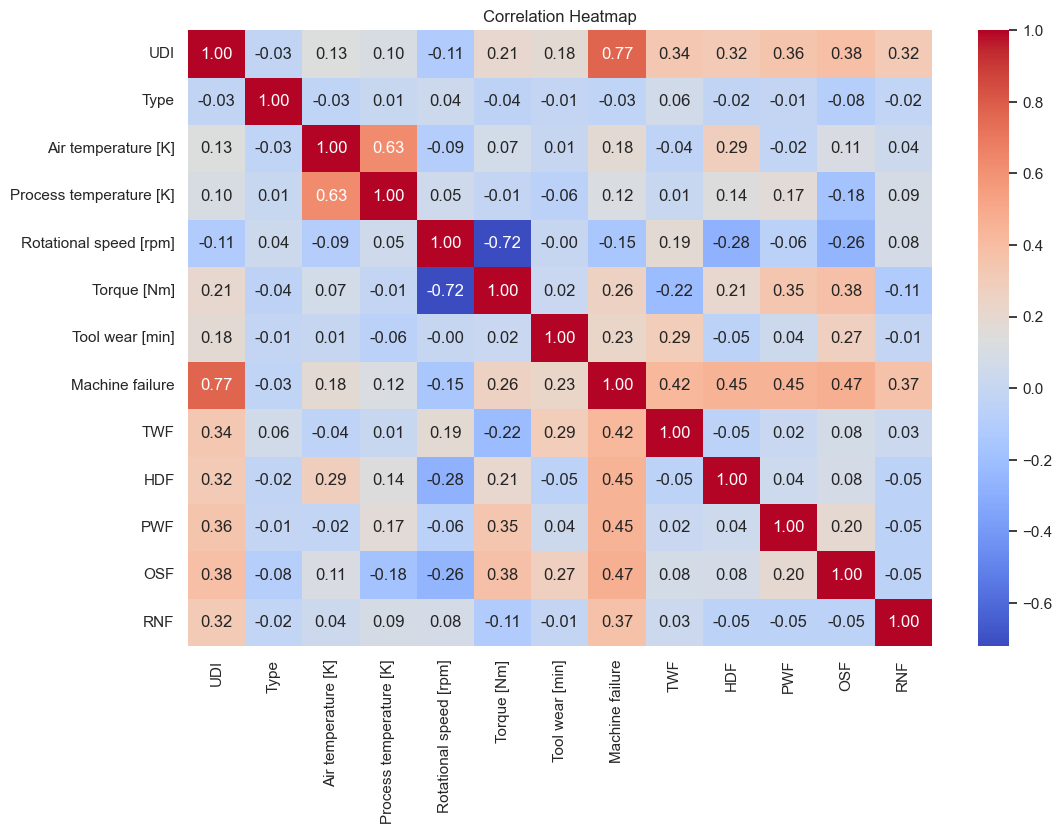

In [13]:
# Create a copy so the original dataset remains unchanged
corr_df = df.copy()

# Convert product type into numbers for correlation analysis
corr_df["Type"] = corr_df["Type"].map({
    "L": 0,
    "M": 1,
    "H": 2
})

# Select numerical columns
corr_matrix = corr_df.select_dtypes(include="number").corr()

# Visualize correlations
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

## 13. Correlation with Machine Failure

In [14]:
# Find how strongly each numerical column correlates with Machine failure
failure_corr = corr_matrix["Machine failure"].sort_values(
    ascending=False
)

print(failure_corr)

Machine failure            1.000000
UDI                        0.767945
OSF                        0.471324
PWF                        0.452690
HDF                        0.449640
TWF                        0.424985
RNF                        0.372302
Torque [Nm]                0.264597
Tool wear [min]            0.231044
Air temperature [K]        0.181694
Process temperature [K]    0.118311
Type                      -0.033335
Rotational speed [rpm]    -0.154289
Name: Machine failure, dtype: float64


## 14. Final EDA Summary

In [15]:
print("Dataset rows:", df.shape[0])
print("Dataset columns:", df.shape[1])

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nMachine failure counts:")
print(df["Machine failure"].value_counts())

print("\nMachine failure percentages:")
print((df["Machine failure"].value_counts(normalize=True) * 100).round(2))

print("\nStrongest correlations with Machine failure:")
print(
    corr_matrix["Machine failure"]
    .drop("Machine failure")
    .abs()
    .sort_values(ascending=False)
    .head(5)
)

Dataset rows: 12500
Dataset columns: 14

Missing values: 0
Duplicate rows: 0

Machine failure counts:
Machine failure
0    9661
1    2839
Name: count, dtype: int64

Machine failure percentages:
Machine failure
0    77.29
1    22.71
Name: proportion, dtype: float64

Strongest correlations with Machine failure:
UDI    0.767945
OSF    0.471324
PWF    0.452690
HDF    0.449640
TWF    0.424985
Name: Machine failure, dtype: float64
